After numeric coercion:
<class 'pandas.DataFrame'>
RangeIndex: 399 entries, 0 to 398
Data columns (total 25 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     390 non-null    float64
 1   bp      387 non-null    float64
 2   sg      352 non-null    float64
 3   al      353 non-null    float64
 4   su      350 non-null    float64
 5   rbc     247 non-null    str    
 6   pc      334 non-null    str    
 7   pcc     395 non-null    str    
 8   ba      395 non-null    str    
 9   bgr     355 non-null    float64
 10  bu      380 non-null    float64
 11  sc      382 non-null    float64
 12  sod     312 non-null    float64
 13  pot     311 non-null    float64
 14  hemo    347 non-null    float64
 15  pcv     328 non-null    float64
 16  wbcc    294 non-null    str    
 17  rbcc    269 non-null    str    
 18  htn     397 non-null    str    
 19  dm      397 non-null    str    
 20  cad     397 non-null    str    
 21  appet   398 non-null    st

c:\Users\prisc\Desktop\CS3IP_Stroke\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\prisc\Desktop\CS3IP_Stroke\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]



Top 10 feature correlations with target:
htn_yes       0.589633
dm_yes        0.548975
al            0.530764
sc            0.512311
appet_poor    0.392645
wbcc_9800     0.391573
rbcc_5.2      0.378290
pe_yes        0.374480
bu            0.360848
bgr           0.349099
dtype: float64

=== Test-set performance (Voting Ensemble) ===
              precision    recall  f1-score   support

           0      1.000     1.000     1.000        60
           1      1.000     1.000     1.000       100

    accuracy                          1.000       160
   macro avg      1.000     1.000     1.000       160
weighted avg      1.000     1.000     1.000       160



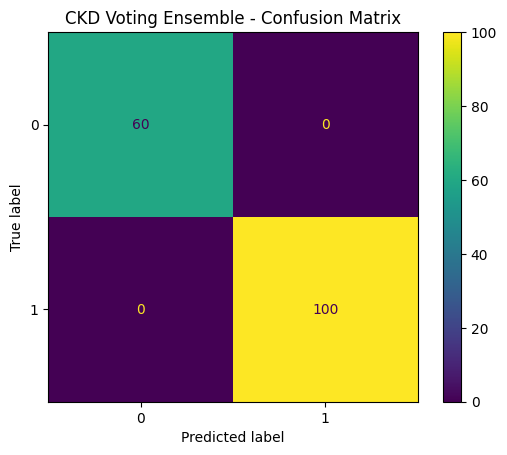


Running 10-fold CV on training set...
10-Fold CV weighted-F1 scores: [1.    0.958 1.    0.958 1.    0.958 0.959 1.    1.    1.   ]
Average Kidney F1 (10-fold): 0.983 ± 0.021


In [16]:
# =============================================================================
# Stroke Risk Prediction - Kidney Dataset (CKD) Adaptation
# Phase: Initial port from Liver V3 pipeline
# Date: ~March 2026
# =============================================================================

# 1. Installs / upgrades (run once, comment out after)
# %pip install --upgrade scikit-learn numpy imbalanced-learn xgboost
# %pip install matplotlib seaborn plotly==5.22.0

# 2. Core imports (same as liver pipeline)
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns

# ────────────────────────────────────────────────
# A. Load & quick clean
# ────────────────────────────────────────────────
df_ckd = pd.read_csv('CKD_cleaned.csv')           # ← make sure this file exists!

# Replace common missing value markers
df_ckd.replace(['?', 'NA', 'nan', ''], np.nan, inplace=True)

# Force numeric columns (very important for CKD dataset)
numeric_cols = ['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 
                'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc']
for col in numeric_cols:
    if col in df_ckd.columns:
        df_ckd[col] = pd.to_numeric(df_ckd[col], errors='coerce')

print("After numeric coercion:")
print(df_ckd.info())

# ────────────────────────────────────────────────
# B. Target mapping – robust version for dirty CKD labels
# ────────────────────────────────────────────────
target_col = 'class'  # confirmed from your .info()

print("Raw value counts in 'class' column BEFORE cleaning:")
print(df_ckd[target_col].value_counts(dropna=False))

# Step 1: Convert to lowercase and strip whitespace/tab junk
df_ckd[target_col] = df_ckd[target_col].astype(str).str.lower().str.strip()

# Step 2: Replace common variations / typos
df_ckd[target_col] = df_ckd[target_col].replace({
    'ckd': 'ckd',
    'ckd\t': 'ckd',           # tab character
    ' ckd ': 'ckd',
    'ckd,t': 'ckd',
    'yes': 'ckd',
    'positive': 'ckd',
    
    'notckd': 'notckd',
    'not ckd': 'notckd',
    'no': 'notckd',
    'notckd\t': 'notckd',
    'negative': 'notckd'
})

# Step 3: Now map to 0/1
mapping = {
    'ckd':     1,
    'notckd':  0
}

df_ckd[target_col] = df_ckd[target_col].map(mapping)

# Step 4: Check for unmapped values (should be empty or very few)
unmapped = df_ckd[target_col].isna()
if unmapped.any():
    print("\n!!! WARNING – Unmapped labels still exist:")
    print(df_ckd.loc[unmapped, target_col].value_counts(dropna=False))
    print("These rows will be dropped.")
    df_ckd = df_ckd.dropna(subset=[target_col])
else:
    print("\nAll labels successfully mapped.")

# Final extraction
y_k = df_ckd[target_col].astype(int)
X_k = df_ckd.drop(columns=[target_col])

print("\nFinal class distribution (0 = healthy, 1 = diseased):")
print(y_k.value_counts(normalize=True).round(3))
print(y_k.value_counts())
# ────────────────────────────────────────────────
# C. Preprocessing pipeline (median imputation + outlier capping like Liver V3)
# ────────────────────────────────────────────────
num_cols = X_k.select_dtypes(include=np.number).columns
cat_cols = X_k.select_dtypes(exclude=np.number).columns

# Numerical: median impute + cap outliers (same logic as Liver)
X_num = X_k[num_cols].copy()
for col in num_cols:
    if X_num[col].notna().sum() == 0:
        continue
    median_val = X_num[col].median()
    Q1, Q3 = X_num[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    X_num.loc[X_num[col] < lower, col] = median_val
    X_num.loc[X_num[col] > upper, col] = median_val
    X_num[col] = X_num[col].fillna(median_val)

# Categorical: most frequent
if len(cat_cols) > 0:
    cat_imputer = SimpleImputer(strategy='most_frequent')
    X_cat = pd.DataFrame(
        cat_imputer.fit_transform(X_k[cat_cols]),
        columns=cat_cols,
        index=X_k.index
    )
    # One-hot encode
    X_cat_encoded = pd.get_dummies(X_cat, drop_first=True)
else:
    X_cat_encoded = pd.DataFrame(index=X_k.index)

# Combine
X_k_clean = pd.concat([X_num, X_cat_encoded], axis=1)

# Final check
print("\nFinal feature shape:", X_k_clean.shape)
print(X_k_clean.isnull().sum().sum(), "missing values left")
# 1. Check if target is accidentally still in features
print("Any column suspiciously named like the target?")
print([c for c in X_k_clean.columns if 'class' in c.lower() or 'ckd' in c.lower()])

# 2. Print shape and first few columns
print("\nX_k_clean shape:", X_k_clean.shape)
print("First 5 column names:", X_k_clean.columns[:5].tolist())
print("Last 5 column names:", X_k_clean.columns[-5:].tolist())

# 3. Correlation of every feature with the target (highest will be suspicious if >0.95)
corrs = X_k_clean.corrwith(y_k).sort_values(ascending=False)
print("\nTop 10 feature correlations with target:")
print(corrs.head(10))

# 4. If you see something ≥ 0.90–0.95 → almost certainly leakage
# ────────────────────────────────────────────────
# D. Train-test split (same as liver: 60/40)
# ────────────────────────────────────────────────
X_train_k, X_test_k, y_train_k, y_test_k = train_test_split(
    X_k_clean, y_k, test_size=0.4, random_state=42, stratify=y_k
)

# Optional: SMOTE if you want to compare (but supervisor prefers weighted / scale_pos_weight)
# sm = SMOTE(random_state=42)
# X_train_res_k, y_train_res_k = sm.fit_resample(X_train_k, y_train_k)

# ────────────────────────────────────────────────
# E. Define base models (reuse best configs from Liver V3 where possible)
# ────────────────────────────────────────────────
lr_pipe = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)
)

rf_pipe = RandomForestClassifier(
    n_estimators=100, max_depth=None, random_state=42, n_jobs=-1
)

svm_pipe = make_pipeline(
    StandardScaler(),
    SVC(kernel='rbf', probability=True, random_state=42)
)

# XGBoost with scale_pos_weight (key for imbalance)
ratio = (y_train_k == 0).sum() / (y_train_k == 1).sum()
xgb_pipe = make_pipeline(
    StandardScaler(),
    XGBClassifier(
        scale_pos_weight=ratio,
        n_estimators=100,
        max_depth=5,
        learning_rate=0.1,
        random_state=42,
        eval_metric='logloss'
    )
)

# ────────────────────────────────────────────────
# F. Voting ensemble — same winning logic from Liver (XGB heavier)
# ────────────────────────────────────────────────
voting_model_k = VotingClassifier(
    estimators=[
        ('SVM', svm_pipe),
        ('RF',  rf_pipe),
        ('LR',  lr_pipe),
        ('XGB', xgb_pipe)
    ],
    voting='soft',
    weights=[1, 1, 1, 2],          # XGB priority — worked best in liver
    n_jobs=-1,
    verbose=True
)

# Fit
voting_model_k.fit(X_train_k, y_train_k)

# Quick test-set performance
print("\n=== Test-set performance (Voting Ensemble) ===")
y_pred_k = voting_model_k.predict(X_test_k)
print(classification_report(y_test_k, y_pred_k, digits=3))

ConfusionMatrixDisplay.from_estimator(voting_model_k, X_test_k, y_test_k)
plt.title("CKD Voting Ensemble - Confusion Matrix")
plt.show()

# ────────────────────────────────────────────────
# G. 10-fold CV on training data (what supervisor specifically asked for)
# ────────────────────────────────────────────────
print("\nRunning 10-fold CV on training set...")
kfold_scores_k = cross_val_score(
    voting_model_k,
    X_train_k, y_train_k,
    cv=10,
    scoring='f1_weighted',
    n_jobs=-1
)

print("10-Fold CV weighted-F1 scores:", kfold_scores_k.round(3))
print(f"Average Kidney F1 (10-fold): {kfold_scores_k.mean():.3f} ± {kfold_scores_k.std():.3f}")